In [2]:
import numpy as np
import matplotlib.pyplot as plt

Analytical:
$$\frac{dp}{dz} = -\frac{gp}{R_dT}$$
$$\frac{dp}{dz} = -\frac{gp}{R_d(T_{sfc}+\gamma z)}$$
$$p(z) = p_0 \left(1 + \frac{\gamma z}{T_{sfc}}\right)^{-\frac{g}{R_d\gamma}}$$

Discrete:
$$p_{i+1} = p_i - \frac{gp_i}{R_dT_{\frac{1}{2}}}\Delta z$$

In [3]:
def p_numerical(z,g = 9.81, Rd = 287.05, Tsfc = 293, gamma = -0.006, p0 = 101800):
    """
    """
    dz = z[1] - z[0]
    # print(fr'\Delta z = ',dz)
    p = np.zeros(len(z))
    p[0] = p0 #pa

    for i in range(len(p)-1):
        T_lower = Tsfc + gamma * z[i]
        T_upper = Tsfc + gamma * z[i+1] 
        T_12 = (T_lower + T_upper) / 2 
        p_new = p[i] - (g * p[i] * dz) / (Rd * T_12)

        p[i+1] = p_new

    return p

def p_analytical(z, g = 9.81, Rd = 287.05, Tsfc = 293, gamma = -0.006, p0 = 101800):

    T = Tsfc + gamma * z

    p = p0 * (T / Tsfc) ** ((-g) / (Rd * gamma))

    return p

<function matplotlib.pyplot.show(close=None, block=None)>

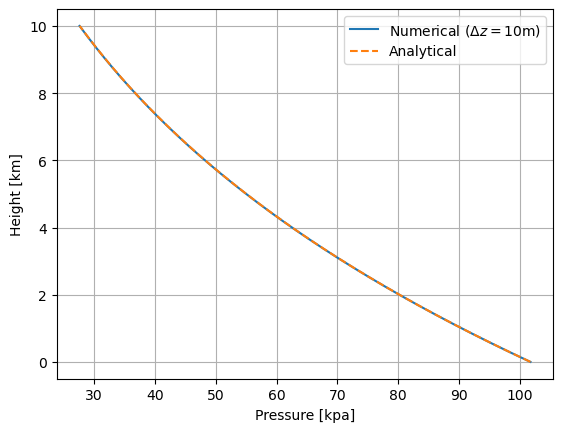

In [4]:
n = 1000
z = np.linspace(0,10000,n+1)
p_num = p_numerical(z)

p_an = p_analytical(z)


plt.plot(p_num / 1000,z/1000, label = fr'Numerical ($\Delta z = {int(z[1]-z[0])}$m)')
plt.plot(p_an / 1000, z / 1000, label = 'Analytical', linestyle = 'dashed')
plt.ylabel('Height [km]')
plt.xlabel('Pressure [kpa]')
# plt.title('Pressure at height for dry atmosphere')

plt.legend()
plt.grid()
plt.savefig('./Figures/Pressure at height2.png', dpi = 300)
plt.show

In [5]:
def density(p,z, Rd = 287.05, Tsfc = 293, gamma = -0.006):

    rho = np.zeros(len(p))

    for i in range(len(z)):
        rho[i] = p[i] / (Rd * (Tsfc + gamma * z[i]))

    return rho

surface density: 1.210km/m3
Density is half of surface at height 6.7km


<function matplotlib.pyplot.show(close=None, block=None)>

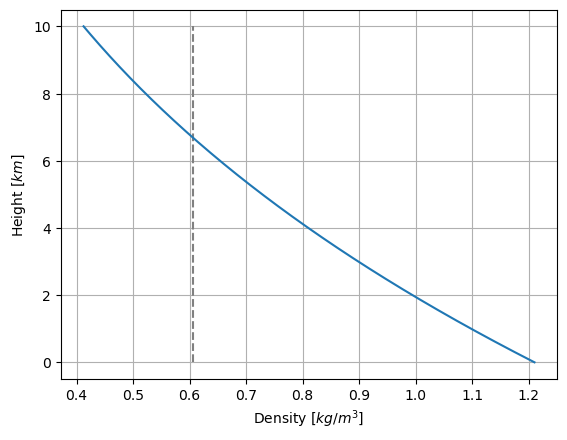

In [6]:
rho = density(p_num,z)

rho_sfc = rho[0]
print(f"surface density: {rho_sfc:.3f}km/m3")

i = 0
while i < len(rho) and rho[i] >= (rho_sfc / 2):
    i += 1
half_rho_z = z[i] if i < len(rho) else None

print(f'Density is half of surface at height {half_rho_z / 1000}km')

plt.plot((rho_sfc / 2) * np.ones(len(rho)), z / 1000, color = 'gray', linestyle = 'dashed')

plt.plot(rho, z / 1000)

plt.xlabel('Density [$kg/m^3$]')
plt.ylabel('Height [$km$]')
# plt.title('Dry air density')
plt.grid()
plt.savefig('./Figures/Dry air density.png', dpi = 300)
plt.show

In [7]:
def vapor_q(p,z, RH, Tsfc = 293, gamma = -0.006, Rd = 287.05, Rv = 461.50):

    T = Tsfc + gamma * z

    e_sat = 610.78 * np.exp((17.2694 * (T - 273.16)) /  (T - 35.86))

    e_vap = RH * e_sat

    q_vap = e_vap / (((Rv / Rd) * (p - e_vap)) + e_vap)

    q_vap = q_vap * 1000 # convert to g/kg

    return q_vap

For Tsfc = 271, q_vap at 5km is 0.369 g/kg
For Tsfc = 303, q_vap at 5km is 5.480 g/kg


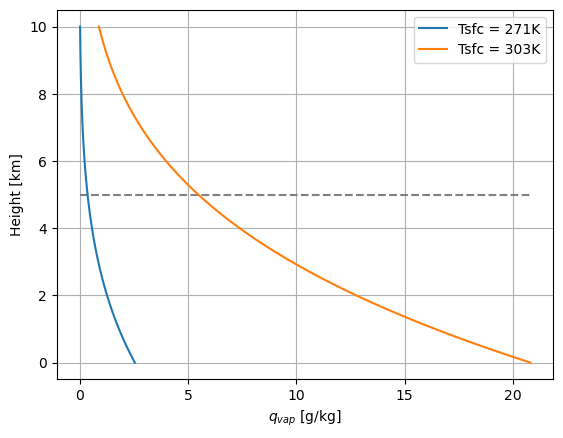

In [8]:
q_vap1 = vapor_q(p_num, z, 0.8, Tsfc = 271)
q_vap2 = vapor_q(p_num, z, 0.8, Tsfc = 303)

plt.plot(np.linspace(0, max(q_vap2), len(q_vap2)), 5 * np.ones(len(q_vap1)), color = 'gray', linestyle = 'dashed')

plt.plot(q_vap1, z / 1000, label = 'Tsfc = 271K')
plt.plot(q_vap2, z / 1000, label = 'Tsfc = 303K')

print(f'For Tsfc = 271, q_vap at 5km is {q_vap1[int(len(z) / 2)]:.3f} g/kg')
print(f'For Tsfc = 303, q_vap at 5km is {q_vap2[int(len(z) / 2)]:.3f} g/kg')

plt.xlabel('$q_{vap}$ [g/kg]')
plt.ylabel('Height [km]')
# plt.title('Specific humidity at height')
plt.legend()
plt.grid()
plt.savefig('./Figures/Specific humidity.png', dpi = 300)
plt.show()

In [9]:
def calculate_WVP(z,
                  RH = 0.8, 
                  Tsfc = 293, 
                  gamma = -0.006, 
                  Rd = 287.05, 
                  Rv = 461.50, 
                  p0 = 101800, 
                  g = 9.81
                  ):
    """
    Compute Water Vapor Path 
    """

    dz = z[1] - z[0]

    # Calculate pressure
    p = p_numerical(z, Tsfc = Tsfc)

    #Calculate density
    rho= density(p,z, Tsfc = Tsfc)

    # Calculate q_v
    q_vap = vapor_q(p,z, RH = RH, Tsfc = Tsfc) / 1000 #convert back to kg/kg

    # Water vavor per layer
    wv = rho * q_vap

    #Trapezoid rule integration
    wvp = 0
    for i in range(len(wv) - 1):
        wvp += ((wv[i] + wv[i+1]) / 2) * dz

    return wvp


Minimum WVP: 2.847 kg m^-2
Maximum WVP: 99.254 kg m^-2


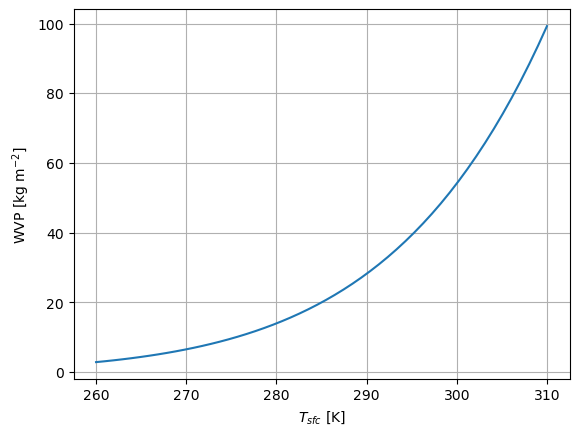

Average dWVP/dT: 7.36% / K
dWVP/dT at global mean temperature (2025) is 7.11%


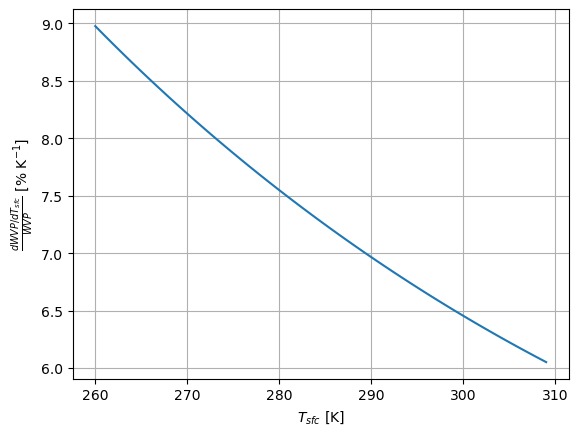

In [10]:
n = 1000
z = np.linspace(0,10000,n+1)

Tsfc_range = np.linspace(260, 310, 52)

wvp_arr = np.zeros(len(Tsfc_range))
for index, i in enumerate(Tsfc_range):
    wvp_arr[index] = calculate_WVP(z,Tsfc = i)

print(f'Minimum WVP: {np.min(wvp_arr):.3f} kg m^-2')
print(f'Maximum WVP: {np.max(wvp_arr):.3f} kg m^-2')
plt.plot(Tsfc_range, wvp_arr)
plt.xlabel('$T_{sfc}$ [K]')
plt.ylabel('WVP [$\\text{kg m}^{-2}$]')
plt.grid()
plt.savefig('./Figures/WVP.png', dpi = 300)
plt.show()

# Calculate dWVP/dTsfc

dwvp = np.zeros(len(wvp_arr) - 1)
for i in range(len(wvp_arr)-1):
    dwvp[i] = wvp_arr[i+1] - wvp_arr[i]

dT = Tsfc_range[1] - Tsfc_range[0]
dWVPdT = dwvp / dT

norm_dWVPdT = dWVPdT / wvp_arr[:-1]

print(f'Average dWVP/dT: {np.mean(norm_dWVPdT)*100:.2f}% / K')
Tavg_global = 287.05

i = 0
while i < len(Tsfc_range) and Tsfc_range[i] <= Tavg_global:
    i += 1
dWVP_at_Tavg = norm_dWVPdT[i]*100 if i < len(rho) else None

print(f'dWVP/dT at global mean temperature (2025) is {dWVP_at_Tavg:.2f}%')


plt.plot(Tsfc_range[:-1], norm_dWVPdT * 100)
plt.xlabel('$T_{sfc}$ [K]')
plt.ylabel('$\\frac{dWVP/dT_{sfc}}{WVP}$ [$\\text{% K}^{-1}$]')
plt.grid()
plt.savefig('./Figures/dWVPdT.png', dpi = 300)
plt.show()

# # -----------------------------------------------
# # Slope method - not sure if correct
# # -----------------------------------------------
# slope, intercept = np.polyfit(Tsfc_range, np.log(wvp_arr), 1)
# rate = (np.exp(slope) - 1) * 100
# print(f"{rate:.1f} % per K")

# plt.plot(Tsfc_range, np.exp(intercept + slope * Tsfc_range), "k--", color = 'gray', label=f"fit: {rate:.1f} %/K")

# plt.plot(Tsfc_range, wvp_arr)
# plt.xlabel('$T_{sfc}$ [K]')
# plt.ylabel('WVP [$\\text{kg m}^{-2}$]')
# plt.yscale('log')
# plt.legend()
# plt.grid()
# plt.show()

Time of rainfall: 2000 s (33.3 min)
Minimum rainfall: 2.85 mm
Maximum rainfall: 99.25 mm
Minimum rainfall rate: 5.13 mm/h
Maximum rainfall rate: 178.66 mm/h


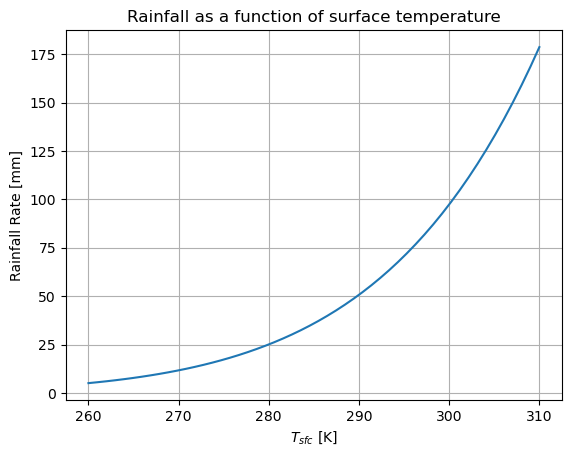

In [ ]:
W = 5       # Vertical velocity [m/s]
H = 10000   # Height of atmospheric column [m]
rho_w = 1000  # Density of liquid water [kg/m3]

# Time needed to rise through the atmosphere
T = H / W  # [s]

# Calculate rainfall
rainfall = []

for Tsfc in Tsfc_range:
    WVP = calculate_WVP(z, Tsfc=Tsfc)  # kg/m2
    rainfall.append((WVP / rho_w) * 1000)     # mm

# Rainfall rate [mm/h]
rainfall_rate = np.array(rainfall) / (T / 3600)

print(f"Time of rainfall: {T:.0f} s ({T/60:.1f} min)")
print(f"Minimum rainfall: {np.min(rainfall):.2f} mm")
print(f"Maximum rainfall: {np.max(rainfall):.2f} mm")
print(f"Minimum rainfall rate: {np.min(rainfall_rate):.2f} mm/h")
print(f"Maximum rainfall rate: {np.max(rainfall_rate):.2f} mm/h")

# Plot rainfall
plt.figure()
plt.plot(Tsfc_range, rainfall_rate)
plt.xlabel('$T_{sfc}$ [K]')
plt.ylabel('Rainfall Rate [mm]')
plt.title('Rainfall as a function of surface temperature')
plt.grid()
plt.savefig('./Figures/Rainfall rate.png', dpi = 300)
plt.show()